# Universidad Autonoma de Aguascalientes
# Departamento: Ciencias de la Computacion
# Carrera: Ingenieria en Computacion Inteligente
## Curso: Sistemas Expertos
## Maestro: Dr.Francisco Javier Lunas Rosas
## Alumno: 
### Semestre: Agosto_Diciembre del 2026

## ¿Que es una convolucíon?

### Una convolución es simplemente una operación matemarica que se realiza sobre los valores de los pixeles de una imagen.

### Se utilizan diferentes nucleos (kernels) o filtros para procesar una imagen hacia una estructura conveniente para realizar cierta tarea o simplemente por estetica.

### Practica 4. Operación matemarica de Convolucion en Imagenes.

### En esta practica implementaremos diferentes nucleos (kernels) o filtros para modificar, analizar o extraer información de una imagen mediante la operación de convolución.

### Paso 1. Añadir las librerias necesarias.

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter


### Paso 2. Especificamos la ruta y cargamos la imagen.

[[136 126 123 ... 180 187 170]
 [104 115 121 ... 176 181 183]
 [104 118 127 ... 175 178 193]
 ...
 [139 140 140 ... 118 115 139]
 [139 140 140 ... 124 122 142]
 [138 139 139 ... 120 105 131]]


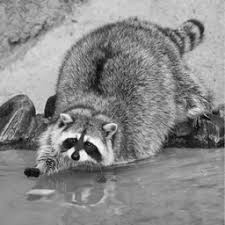

In [5]:
os.chdir("C:\\Users\\silva\\Downloads")
with Image.open("mapache.png") as im:
    pixel_array = np.array(im, dtype = "uint8")

print(pixel_array)
im

### Paso 3. Cargamos la imgane desde un Archivo *.csv. Cargamos el archivo en forma csv que contiene la representación de pixeles de la imagen mapache.jpeg.

In [6]:
dt_mapache = pd.read_csv("mapache.csv", sep = ';', decimal = '.')
dt_mapache 

,136,126,123,129,129.1,121,121.1,127,111,124,...,186.2,193.4,196.4,195.3,188.1,179.1,176,180.1,187.3,170.1
0,104,115,121,123,129,134,126,111,124,124,...,186,197,199,197,188,178,174,176,181,183
1,104,118,127,126,126,131,129,121,139,128,...,186,199,199,195,187,178,174,175,178,193
2,130,134,145,151,141,126,127,138,144,136,...,186,195,193,189,184,180,178,179,181,193
3,142,143,154,167,164,146,133,131,141,146,...,186,186,183,181,180,182,185,187,187,192
4,150,151,149,150,161,166,149,125,142,151,...,185,181,177,174,177,183,189,191,190,195
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,139,140,140,141,142,143,143,144,144,144,...,129,128,129,129,128,126,121,117,114,143
220,139,140,140,141,142,143,143,144,144,144,...,134,132,132,131,129,124,119,113,110,138
221,139,140,140,141,142,143,143,144,144,144,...,135,131,131,132,130,127,122,118,115,139
222,139,140,140,141,142,143,143,144,144,144,...,130,128,129,131,131,130,127,124,122,142


### Paso 4. Convertimos un Array a una imagen.

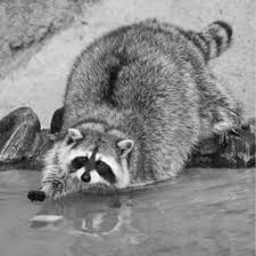

In [7]:
im = Image.fromarray(np.array(dt_mapache, dtype=np.uint8), mode = 'L')
im.resize((256,256))

### Paso 5. Aplicamos Filtros o Nucleos. Vamos a utilizar la funcion kernel() del modelo Imagen Filter y la funcion filter() del modelo Image.

### 5.1 Filtro de Identidad. El filtro de identidad en imagenes es el mas simple de todos: no cambia la imagen. Su funcin es devolver exactamente la misma imagen despues de aplicar la convolucion. Solo toma el valor del pixel central e ignora los vecinos.

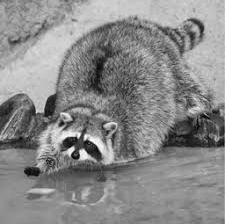

In [8]:
km = [0,0,0,
      0,1,0,
      0,0,0]
k = ImageFilter.Kernel(size=(3,3), kernel=km, scale = 1)

im2 = im.filter(k)
im2

### Paso 5.2 Desenfoque: El filtro de desenfoque (blur) se usa para suavizar una imagen, reduciendo detalles finos y variaciones bruscas entre piceles. Toma cada pixel y lo remplaza por un promedio de sus vecionos.

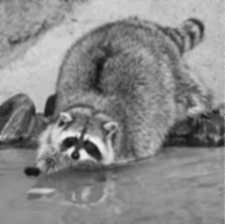

In [9]:
km = [1,1,1,
      1,1,1,
      1,1,1]

# Utilize diferente escala.

k = ImageFilter.Kernel(size=(3,3), kernel=km, scale = 9)

im2 = im.filter(k)
im2

### Paso 5.3 Enfoque. El filtro de enfoque (sharpen) se usa oara resaltar los detalles y hacer que una imagen se cea mas nitida. Hace que las zonas donde hay cambios (borde, texturas) se vean mas marcadas. 

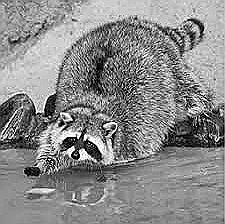

In [10]:
km = (
    0, -1, 0,
    -1, 5, -1,
    0, -1, 0
)
k = ImageFilter.Kernel(size=(3,3), kernel=km, scale = 1)

im2 = im.filter(k)
im2

### Paso 5.4 Emboss. El filtro de emboss (relieve) se usa para darle a la imagen un efecto tridimensional como si estuviera grabada o tallada en una superficie. Resalta bordes y sombras para simular profundida (luz y relieve).

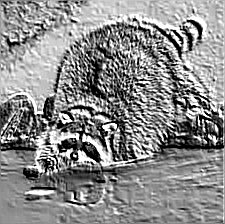

In [11]:
km = (
    -2, -1, 0,
    -1, 1, 1,
    0, 1, 2
)
k = ImageFilter.Kernel(size=(3,3), kernel=km, scale = 1)

im2 = im.filter(k)
im2

### 5.5 Laplace

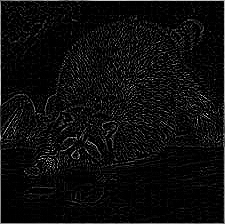

In [12]:
km = (
     0,  1,  0,
     1, -4,  1,
     0,  1,  0
)
k = ImageFilter.Kernel(size=(3,3), kernel=km, scale = 1)

im2 = im.filter(k)
im2

### 5.6 Prewitt Horizontal

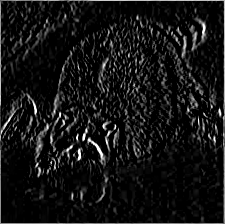

In [ ]:
km = (
    -1, -1, -1,
     0,  0,  0,
     1,  1,  1
)
k = ImageFilter.Kernel(size=(3, 3), kernel=km, scale=1)

im2 = im.filter(k)
im2

### 5.6 Prewitt Vertical

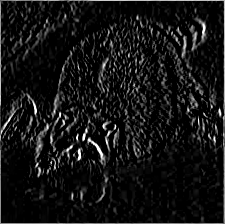

In [15]:
km = (
    -1,  0,  1,
    -1,  0,  1,
    -1,  0,  1
)
k = ImageFilter.Kernel(size=(3, 3), kernel=km, scale=1)

im2 = im.filter(k)
im2

### 5.7 Sobel Horizontal

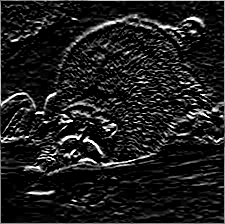

In [16]:
km = (
    -1, -2, -1,
     0,  0,  0,
     1,  2,  1
)
k = ImageFilter.Kernel(size=(3, 3), kernel=km, scale=1)

im2 = im.filter(k)
im2

### 5.7 Sobel Vertical

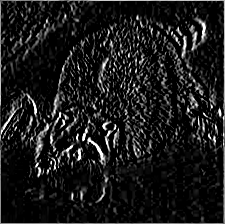

In [17]:
km = (
    -1,  0,  1,
    -2,  0,  2,
    -1,  0,  1
)
k = ImageFilter.Kernel(size=(3, 3), kernel=km, scale=1)

im2 = im.filter(k)
im2

### 5.8 Roberts.

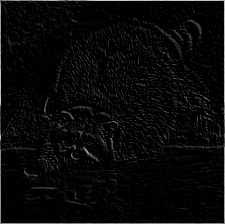

In [18]:
km = (
     1,  0,  0,
     0, -1,  0,
     0,  0,  0
)
k = ImageFilter.Kernel(size=(3, 3), kernel=km, scale=1)

im2 = im.filter(k)
im2

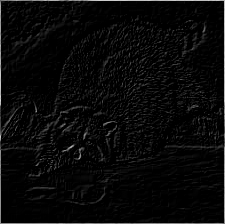

In [19]:
km = (
     0,  1,  0,
    -1,  0,  0,
     0,  0,  0
)
k = ImageFilter.Kernel(size=(3, 3), kernel=km, scale=1)

im2 = im.filter(k)
im2

## Conclusiones.

### En esta practica implementamos diferentes nucleos (kernels) o filtros para modificar, analizar o extraer información de una imagen mediante la operación de convolución.

## Referencias

### URL: Imagenes en Python, (Pillow 2026)
https://pillow.readthedocs.io/en/stable/ (Ultimo acceso Octubre de 2026).